# Fine-Tuning de RFDETR NANO

Luegod del análisis del modelo seleccionado, se evidenciaron grandes problemas en el momento de tratar con muestras sin anotaciones, generando alta cantidad de Falsos Positivos (FP), se toma la desición de realizar un Fine-Tuning al modelo con muestras sin anotaciones para evaluar si se mejora el desempeño

## Preparar entorno

In [1]:
%pip -q install "rfdetr[train]==1.12.0" "kagglehub==1.0.3" soundfile

In [2]:
from pathlib import Path
from google.colab import drive
from scipy.signal import stft
from PIL import Image
from tqdm.auto import tqdm
from rfdetr.config import RFDETRNanoConfig, TrainConfig
from rfdetr.training import RFDETRModelModule, RFDETRDataModule, build_trainer
from rfdetr.training.callbacks.best_model import BestModelCallback, RFDETREarlyStopping
import numpy as np
import pandas as pd
import kagglehub
import soundfile as sf
import hashlib
import zipfile
import json
import torch
import gc

drive.mount("/content/drive")

SEED = 0
FS, VENTANA_S, SALTO_S = 32000, 8, 4
BASE_LOCAL = Path("/content/proyecto_aves/rfdetr_07b")
BASE_DRIVE = Path("/content/drive/MyDrive/Proyecto_Aves")
DIR_E3 = BASE_DRIVE / "experiments/detector/E3_RFDETR_Nano/final_v1"
DIR_07B = BASE_DRIVE / "experiments/detector/E5_RFDETR_Negativas"
DIR_DATOS = BASE_LOCAL / "dataset"
DIR_PARTES = BASE_LOCAL / "partes"
DIR_ZIPS = BASE_LOCAL / "zips"
DATASET = "santiagocorrea802/dataset-proyecto"
NOTEBOOK_KAGGLE = "santiagocorrea802/notebook1240c3d28f/versions/1"

for carpeta in (DIR_07B, DIR_DATOS, DIR_PARTES, DIR_ZIPS):
    carpeta.mkdir(parents=True, exist_ok=True)

print("Experimento:", DIR_07B)

/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


Mounted at /content/drive
Experimento: /content/drive/MyDrive/Proyecto_Aves/experiments/detector/E5_RFDETR_Negativas


## Recuperar seleccion de ventanas negativas

In [3]:
DATASET_NEG = "santiagocorrea802/rfdetr-negativas-train-v1"
splits = pd.read_csv(BASE_DRIVE / "splits/recording_split_seed0.csv")
ruta = kagglehub.dataset_download(DATASET_NEG, path="seleccion_negativas.csv", output_dir=str(BASE_LOCAL))
seleccion = pd.read_csv(ruta)
seleccion.to_csv(DIR_07B / "seleccion_negativas_opt_v1.csv", index=False)

print("Ventanas negativas seleccionadas:", len(seleccion))
display(seleccion["dataset"].value_counts())

100%|██████████| 208k/208k [00:00<00:00, 959kB/s]


Ventanas negativas seleccionadas: 1798


,count
dataset,
Col-CR,500
PteroSet,500
Peru,438
WABAD-CO,360


## Descargar espectrogramas negativos

In [4]:
import shutil

PARTES = [1, 2, 13, 14, 15, 16]

for i in PARTES:
    nombre = f"yolo11n_completo_parte_{i:02d}"
    carpeta = DIR_PARTES / nombre
    esperado = 1255 if i == 16 else 3000

    if len(list(carpeta.rglob("*.png"))) != esperado or len(list(carpeta.rglob("*.txt"))) != esperado:
        if carpeta.exists():
            shutil.rmtree(carpeta)

        archivo = Path(kagglehub.notebook_output_download(
            NOTEBOOK_KAGGLE, path=f"{nombre}.zip", output_dir=str(DIR_ZIPS)
        ))

        with zipfile.ZipFile(archivo) as z:
            nombres = [p for p in z.namelist() if p.endswith(".png")]
            incluye_carpeta = all(Path(p).parts[0] == nombre for p in nombres)
            z.extractall(DIR_PARTES if incluye_carpeta else carpeta)

    if len(list(carpeta.rglob("*.png"))) != esperado or len(list(carpeta.rglob("*.txt"))) != esperado:
        raise ValueError(f"Parte {i:02d} incompleta")

    print("Parte preparada:", i)


for destino in ("train", "valid"):
    for tipo in ("images", "labels"):
        (DIR_DATOS / destino / tipo).mkdir(parents=True, exist_ok=True)

for i in PARTES:
    carpeta = DIR_PARTES / f"yolo11n_completo_parte_{i:02d}"
    for origen_split, destino_split in (("train", "train"), ("val", "valid")):
        if destino_split == "train" and i not in (1, 2):
            continue

        for imagen in (carpeta / "images" / origen_split).glob("*.png"):
            etiqueta = carpeta / "labels" / origen_split / f"{imagen.stem}.txt"
            for fuente, destino in ((imagen, DIR_DATOS / destino_split / "images" / imagen.name), (etiqueta, DIR_DATOS / destino_split / "labels" / etiqueta.name)):
                if not destino.exists():
                    destino.symlink_to(fuente.resolve())

(DIR_DATOS / "data.yaml").write_text("train: train/images\nval: valid/images\nnc: 1\nnames: [BIRD_EVENT]\n", encoding="utf-8")
print("Positivas train:", len(list((DIR_DATOS / "train/images").glob("*.png"))))
print("Positivas validation:", len(list((DIR_DATOS / "valid/images").glob("*.png"))))

100%|██████████| 1.14G/1.14G [00:42<00:00, 29.0MB/s]


Parte preparada: 1


100%|██████████| 1.14G/1.14G [00:38<00:00, 31.6MB/s]


Parte preparada: 2


100%|██████████| 1.14G/1.14G [00:46<00:00, 26.5MB/s]


Parte preparada: 13


... (2 outputs left out)

100%|██████████| 1.14G/1.14G [00:41<00:00, 29.3MB/s]


Parte preparada: 15


100%|██████████| 489M/489M [00:19<00:00, 26.0MB/s]


Parte preparada: 16
Positivas train: 6000
Positivas validation: 8113


## Recuperar espectogramas negativos

Usaremos exactamente la función de generación que reprodujo el PNG original con MAE igual a cero.

Las anotaciones negativas serán archivos .txt vacíos: ese es el formato que RF-DETR admite para imágenes sin objetos anotados

In [13]:
raiz = Path(kagglehub.dataset_download(DATASET_NEG))
dir_imagenes = DIR_DATOS / "train/images"
dir_etiquetas = DIR_DATOS / "train/labels"

archivo_zip = next(raiz.rglob("negativas_train.zip"), None)

if archivo_zip is not None:
    with zipfile.ZipFile(archivo_zip) as z:
        z.extractall(DIR_DATOS / "train")
else:
    ejemplo = f"{seleccion['archivo'].iloc[0]}.png"
    origen = next((p for p in raiz.rglob("images") if (p / ejemplo).is_file()), None)

    if origen is None:
        raise FileNotFoundError(f"No se encontraron los PNG en {raiz}: {list(raiz.iterdir())}")

    for nombre in seleccion["archivo"]:
        imagen = origen / f"{nombre}.png"
        destino = dir_imagenes / imagen.name

        if not destino.exists():
            destino.symlink_to(imagen.resolve())

        (dir_etiquetas / f"{nombre}.txt").touch(exist_ok=True)

assert all(
    (dir_imagenes / f"{nombre}.png").is_file() and
    (dir_etiquetas / f"{nombre}.txt").is_file()
    for nombre in seleccion["archivo"]
)

print("Positivas train:", len(list(dir_imagenes.glob("*.png"))) - len(seleccion))
print("Negativas train:", len(seleccion))
print("Positivas validation:", len(list((DIR_DATOS / "valid/images").glob("*.png"))))

Using Colab cache for faster access to the 'rfdetr-negativas-train-v1' dataset.
Positivas train: 6000
Negativas train: 1798
Positivas validation: 8113


**Comprobacion breve**

In [14]:
asignaciones = splits.groupby("recording_uid")["split"].nunique()
assert (asignaciones == 1).all(), "Hay grabaciones en varios splits"

train_ids = set(splits.loc[splits["split"] == "train", "recording_uid"])
val_ids = set(splits.loc[splits["split"] == "validation", "recording_uid"])
test_ids = set(splits.loc[splits["split"] == "test", "recording_uid"])

assert not (train_ids & val_ids or train_ids & test_ids or val_ids & test_ids)
assert set(seleccion["recording_uid"]).issubset(train_ids)

print("Separacion de grabaciones correcta")

Separacion de grabaciones correcta


## Configurar Fine-Tuning

Conservaremos la arquitectura, resolución, selección por AP50 y gran parte de la configuración original, pero reduciremos la tasa de aprendizaje porque partimos de un detector ya entrenado.

In [15]:
RUTA_MODELO = DIR_E3 / "checkpoint_best_total.pth"
DIR_RUN = DIR_07B / "entrenamiento_v2"
DIR_RUN.mkdir(parents=True, exist_ok=True)

CONFIG = {
    "modelo": "RFDETRNano",
    "checkpoint_inicial": str(RUTA_MODELO),
    "train_positivas": 6000,
    "train_negativas": len(seleccion),
    "validation": 8113,
    "epochs": 10,
    "early_stopping_patience": 4,
    "early_stopping_min_delta": 0.001,
    "batch_size": 4,
    "grad_accum_steps": 4,
    "resolution": 384,
    "lr": 2e-5,
    "lr_encoder": 1e-5,
    "weight_decay": 1e-4,
    "seed": SEED,
    "metrica": "val/ema_mAP_50"
}

(DIR_RUN / "configuracion.json").write_text(json.dumps(CONFIG, indent=2), encoding="utf-8")

print("Checkpoint inicial:", RUTA_MODELO)
print("Dataset:", DIR_DATOS)
print("Salida:", DIR_RUN)

Checkpoint inicial: /content/drive/MyDrive/Proyecto_Aves/experiments/detector/E3_RFDETR_Nano/final_v1/checkpoint_best_total.pth
Dataset: /content/proyecto_aves/rfdetr_07b/dataset
Salida: /content/drive/MyDrive/Proyecto_Aves/experiments/detector/E5_RFDETR_Negativas/entrenamiento_v2


## Ejecutar entrenamiento

In [17]:
checkpoints = sorted(DIR_RUN.glob("checkpoint_*.ckpt"), key=lambda p: int(p.stem.split("_")[-1]))
RUTA_LAST = checkpoints[-1] if checkpoints else DIR_RUN / "last.ckpt"
RUTA_BEST = DIR_RUN / "checkpoint_best_total.pth"
RUTA_ESTADO = DIR_RUN / "estado.json"
if not RUTA_ESTADO.is_file() and (DIR_RUN / "metrics.csv").is_file() and not RUTA_LAST.is_file():
    raise RuntimeError("Existe un entrenamiento incompleto sin checkpoint de recuperacion")

if RUTA_ESTADO.is_file():
    print("Entrenamiento completado previamente")
else:
    modelo_config = RFDETRNanoConfig(num_classes=1, resolution=384, pretrain_weights=str(RUTA_MODELO))
    train_config = TrainConfig(dataset_dir=str(DIR_DATOS), output_dir=str(DIR_RUN), epochs=CONFIG["epochs"], batch_size=CONFIG["batch_size"], eval_batch_size=2,
                               grad_accum_steps=CONFIG["grad_accum_steps"], lr=CONFIG["lr"], lr_encoder=CONFIG["lr_encoder"], weight_decay=CONFIG["weight_decay"],
                               num_workers=2, seed=SEED, optimizer="adamw", lr_scheduler="cosine", warmup_epochs=1, checkpoint_interval=3, use_ema=True, eval_base_model=False,
                               early_stopping=True, early_stopping_patience=CONFIG["early_stopping_patience"], early_stopping_min_delta=CONFIG["early_stopping_min_delta"], tensorboard=False, run_test=False, aug_config={}, scale_jitter=False, multi_scale=False, augmentation_backend="torchvision")

    modulo = RFDETRModelModule(modelo_config, train_config)
    datos = RFDETRDataModule(modelo_config, train_config)
    entrenador = build_trainer(train_config, modelo_config)

    for i, callback in enumerate(entrenador.callbacks):
        if isinstance(callback, BestModelCallback):
            entrenador.callbacks[i] = BestModelCallback(output_dir=str(DIR_RUN), monitor_regular="val/mAP_50", monitor_ema="val/ema_mAP_50", run_test=False, evaluates_base_model=False)
        elif isinstance(callback, RFDETREarlyStopping):
            entrenador.callbacks[i] = RFDETREarlyStopping(patience=CONFIG["early_stopping_patience"], min_delta=CONFIG["early_stopping_min_delta"], use_ema=True, monitor_regular="val/mAP_50", monitor_ema="val/ema_mAP_50")

    reanudacion = str(RUTA_LAST) if RUTA_LAST.is_file() else None
    entrenador.fit(modulo, datos, ckpt_path=reanudacion)

    if not RUTA_BEST.is_file():
        raise FileNotFoundError("No se guardo el mejor checkpoint")

    RUTA_ESTADO.write_text(json.dumps({"finalizado": True}), encoding="utf-8")
    print("Fine-tuning completado")

    del entrenador, modulo, datos
    gc.collect()

Val (ema) (Epoch 5/10) — Overall Metrics            
┏━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃           mAP            ┃  mAR   ┃         F1 sweep         ┃
┡━━━━━━━━┯━━━━━━━━┯━━━━━━━━╇━━━━━━━━╇━━━━━━━━┯━━━━━━━━┯━━━━━━━━┩
│ 50:95  │   50   │   75   │  @500  │   F1   │  Prec  │ Recall │
├────────┼────────┼────────┼────────┼────────┼────────┼────────┤
│ 0.2053 │ 0.4569 │ 0.1537 │ 0.5110 │ 0.4925 │ 0.5202 │ 0.4675 │
└────────┴────────┴────────┴────────┴────────┴────────┴────────┘

INFO:pytorch_lightning.callbacks.early_stopping:Monitored metric __rfdetr_effective_map__ did not improve in the last 4 records. Best score: 0.466. Signaling Trainer to stop.


[2026-11-19 05:40:36] [INFO] rf-detr - Best total checkpoint saved from EMA (regular=0.0000, ema=0.4659)
Fine-tuning completado


## Recuperar resultados

In [18]:
metricas = pd.read_csv(DIR_RUN / "metrics.csv")

for columna in ("val/ema_mAP_50", "val/mAP_50"):
    if columna in metricas.columns:
        valores = pd.to_numeric(metricas[columna], errors="coerce").dropna()
        if not valores.empty:
            print(f"{columna}: {valores.max():.4f}")

print("Mejor checkpoint:", RUTA_BEST)
print("Entrenamiento completado:", RUTA_ESTADO.is_file())

val/ema_mAP_50: 0.4659
val/mAP_50: 0.4659
Mejor checkpoint: /content/drive/MyDrive/Proyecto_Aves/experiments/detector/E5_RFDETR_Negativas/entrenamiento_v2/checkpoint_best_total.pth
Entrenamiento completado: True


El mejor resultado se obtuvo en la primera época. Como las cuatro siguientes no lograron una mejora suficiente, el entrenamiento se detuvo y conservó los mejores pesos.

### Conclusiones

Se realizó un ajuste fino de RF-DETR Nano incorporando 1.798 ventanas sin anotaciones y 6.000 ventanas positivas del conjunto de entrenamiento. El modelo fue inicializado con los mejores pesos del experimento E3

El entrenamiento finalizó después de 5 épocas debido a la parada temprana, obteniendo su mejor AP50 de 0.4659 durante la primera época. Este resultado es ligeramente inferior al AP50 de 0.4687 obtenido por el modelo original.

Sin embargo, el objetivo principal del experimento fue reducir las falsas detecciones, no necesariamente aumentar el AP50. Por tanto, todavía no es posible determinar si el ajuste fino produjo una mejora operativa.

Como siguiente etapa, se compararán ambos modelos sobre las mismas grabaciones completas de validación, analizando principalmente el recall y los falsos positivos por hora (FP/h).

## Evaluacion operativa del modelo ajustado

Se compara RF-DETR Nano original (E3) con el modelo ajustado con ventanas sin anotaciones (E5), utilizando las mismas grabaciones de validacion y los mismos criterios de evaluacion.

In [19]:
%pip -q install "rfdetr==1.12.0" "kagglehub==1.0.3" soundfile

from pathlib import Path
from google.colab import drive
from scipy.signal import stft
from PIL import Image
from tqdm.auto import tqdm
from rfdetr import RFDETRNano
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import soundfile as sf
import kagglehub
import torch
import hashlib
import json
import gc

drive.mount("/content/drive")

BASE_DRIVE = Path("/content/drive/MyDrive/Proyecto_Aves")
BASE_LOCAL = Path("/content/proyecto_aves")
DIR_E4 = BASE_DRIVE / "experiments/detector/E4_Comparacion_v1/evaluacion_operativa_v1"
DIR_RUN = BASE_DRIVE / "experiments/detector/E5_RFDETR_Negativas/entrenamiento_v2"
RUTA_MODELO = DIR_RUN / "checkpoint_best_total.pth"

with RUTA_MODELO.open("rb") as archivo:
    ID_MODELO = hashlib.file_digest(archivo, "sha256").hexdigest()[:12]

DIR_EVAL = DIR_RUN / "evaluacion_operativa_v1" / ID_MODELO
DIR_BLOQUES = DIR_EVAL / "predicciones"
DIR_BLOQUES.mkdir(parents=True, exist_ok=True)

indice = pd.read_csv(DIR_E4 / "ventanas_validation.csv").sort_values(["recording_uid", "ventana_id"]).reset_index(drop=True)
catalogo = pd.read_csv(DIR_E4 / "grabaciones_validation.csv")
datos_e3 = torch.load(DIR_E4 / "datos_analisis.pt", map_location="cpu", weights_only=True)

gt = {uid: cajas.numpy() for uid, cajas in datos_e3["gt"].items()}
pred_e3 = {uid: cajas.numpy() for uid, cajas in datos_e3["pred_iou"].items()}

HORAS_AUDIO = catalogo["duration_sec"].sum() / 3600
FS, VENTANA_S, CONF_MIN, MAX_DETECCIONES, BLOQUE = 32000, 8, 0.05, 100, 128

print("Grabaciones:", len(catalogo))
print("Ventanas:", len(indice))
print("Horas de audio:", round(HORAS_AUDIO, 2))
print("Resultados:", DIR_EVAL)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Grabaciones: 152
Ventanas: 17962
Horas de audio: 20.13
Resultados: /content/drive/MyDrive/Proyecto_Aves/experiments/detector/E5_RFDETR_Negativas/entrenamiento_v2/evaluacion_operativa_v1/20f2d1c6100b


### Inferencia sobre grabaciones de validacion

In [20]:
def imagen_desde_audio(audio):
    _, _, z = stft(audio, fs=FS, nperseg=1024, noverlap=768, boundary=None)
    db = 20 * np.log10(np.maximum(np.abs(z), 1e-8))
    vmax = np.percentile(db, 99)
    espectrograma = np.flipud(np.clip((db - (vmax - 80)) / 80, 0, 1))
    return Image.fromarray(np.rint(espectrograma * 255).astype(np.uint8)).convert("RGB")

def descargar_audio(ruta):
    ruta = str(ruta).replace("\\", "/")
    if not ruta.startswith("DATASET_PROYECTO/"):
        ruta = f"DATASET_PROYECTO/{ruta}"
    return Path(kagglehub.dataset_download("santiagocorrea802/dataset-proyecto", path=ruta, output_dir=str(BASE_LOCAL)))

def guardar_salidas(predicciones, imagenes):
    salidas = modelo.predict(imagenes, threshold=CONF_MIN)
    for imagen, salida in zip(imagenes, salidas):
        ancho, alto = imagen.size
        escala = np.array([ancho, alto, ancho, alto], dtype=np.float32)
        cajas = np.asarray(salida.xyxy, dtype=np.float32).reshape(-1, 4) / escala
        scores = np.asarray(salida.confidence, dtype=np.float32).reshape(-1)
        orden = np.argsort(-scores)[:MAX_DETECCIONES]
        predicciones.append({
            "boxes": torch.from_numpy(cajas[orden].copy()),
            "scores": torch.from_numpy(scores[orden].copy())
        })

configuracion = json.loads((DIR_RUN / "configuracion.json").read_text(encoding="utf-8"))
modelo = RFDETRNano(pretrain_weights=str(RUTA_MODELO), num_classes=1, resolution=int(configuracion["resolution"]))
DIR_PNG_VAL = BASE_LOCAL / "rfdetr_07b/dataset/valid/images"

for inicio in tqdm(range(0, len(indice), BLOQUE), desc="Inferencia E5"):
    salida = DIR_BLOQUES / f"{inicio:05d}.pt"
    if salida.is_file():
        continue

    bloque = indice.iloc[inicio:inicio + BLOQUE]
    predicciones = []

    for uid, grupo in bloque.groupby("recording_uid", sort=False):
        archivo_audio = None
        imagenes = []

        for fila in grupo.itertuples(index=False):
            png = DIR_PNG_VAL / f"{fila.archivo}.png"

            if fila.con_anotacion and png.is_file():
                with Image.open(png) as imagen:
                    imagenes.append(imagen.convert("RGB"))
            else:
                if archivo_audio is None:
                    archivo_audio = sf.SoundFile(descargar_audio(fila.normalized_path))

                archivo_audio.seek(int(fila.inicio_muestra))
                audio = archivo_audio.read(FS * VENTANA_S, dtype="float32")

                if len(audio) < FS * VENTANA_S:
                    audio = np.pad(audio, (0, FS * VENTANA_S - len(audio)))

                imagenes.append(imagen_desde_audio(audio))

            if len(imagenes) == 2:
                guardar_salidas(predicciones, imagenes)
                imagenes = []

        if imagenes:
            guardar_salidas(predicciones, imagenes)

        if archivo_audio is not None:
            archivo_audio.close()

    temporal = salida.with_suffix(".tmp")
    torch.save(predicciones, temporal)
    temporal.replace(salida)

print("Inferencia E5 completada")
del modelo
gc.collect()

Inferencia E5:   0%|          | 0/141 [00:00<?, ?it/s]


  0%|          | 0.00/108M [00:00<?, ?B/s]
  1%|          | 1.00M/108M [00:00<00:41, 2.72MB/s]
  3%|▎         | 3.00M/108M [00:00<00:14, 7.48MB/s]
  8%|▊         | 9.00M/108M [00:00<00:04, 21.5MB/s]
 12%|█▏        | 13.0M/108M [00:00<00:03, 25.0MB/s]
 17%|█▋        | 18.0M/108M [00:00<00:03, 30.3MB/s]
 21%|██▏       | 23.0M/108M [00:01<00:03, 28.4MB/s]
 25%|██▌       | 27.0M/108M [00:01<00:03, 24.8MB/s]
 32%|███▏      | 34.0M/108M [00:01<00:02, 33.0MB/s]
 38%|███▊      | 41.0M/108M [00:01<00:01, 39.4MB/s]
 43%|████▎     | 46.0M/108M [00:01<00:01, 38.1MB/s]
 47%|████▋     | 51.0M/108M [00:01<00:01, 40.1MB/s]
 54%|█████▍    | 58.0M/108M [00:01<00:01, 45.1MB/s]
 59%|█████▊    | 63.0M/108M [00:02<00:01, 37.2MB/s]
 65%|██████▌   | 70.0M/108M [00:02<00:00, 42.5MB/s]
 71%|███████   | 76.0M/108M [00:02<00:00, 47.1MB/s]
 76%|███████▌  | 82.0M/108M [00:02<00:00, 49.5MB/s]
 82%|████████▏ | 88.0M/108M [00:02<00:00, 50.4MB/s]
 87%|████████▋ | 94.0M/108M [00:02<00:00, 47.5MB/s]
 93%|█████████▎| 100


  0%|          | 0.00/111M [00:00<?, ?B/s]
  1%|          | 1.00M/111M [00:00<00:43, 2.66MB/s]
  3%|▎         | 3.00M/111M [00:00<00:15, 7.42MB/s]
  8%|▊         | 9.00M/111M [00:00<00:04, 21.5MB/s]
 12%|█▏        | 13.0M/111M [00:00<00:03, 25.8MB/s]
 15%|█▌        | 17.0M/111M [00:00<00:03, 29.1MB/s]
 20%|█▉        | 22.0M/111M [00:00<00:02, 34.2MB/s]
 24%|██▍       | 27.0M/111M [00:01<00:02, 38.5MB/s]
 31%|███       | 34.0M/111M [00:01<00:01, 45.1MB/s]
 37%|███▋      | 41.0M/111M [00:01<00:01, 39.8MB/s]
 43%|████▎     | 48.0M/111M [00:01<00:01, 44.9MB/s]
 48%|████▊     | 53.0M/111M [00:01<00:01, 44.3MB/s]
 54%|█████▍    | 60.0M/111M [00:01<00:01, 48.3MB/s]
 59%|█████▉    | 65.0M/111M [00:02<00:01, 33.8MB/s]
 62%|██████▏   | 69.0M/111M [00:02<00:01, 33.2MB/s]
 66%|██████▌   | 73.0M/111M [00:02<00:01, 26.6MB/s]
 71%|███████   | 78.0M/111M [00:02<00:01, 30.6MB/s]
 77%|███████▋  | 85.0M/111M [00:02<00:00, 37.3MB/s]
 82%|████████▏ | 91.0M/111M [00:02<00:00, 39.6MB/s]
 89%|████████▊ | 98.


  0%|          | 0.00/107M [00:00<?, ?B/s]
  1%|          | 1.00M/107M [00:00<00:42, 2.58MB/s]
  3%|▎         | 3.00M/107M [00:00<00:15, 7.19MB/s]
  8%|▊         | 9.00M/107M [00:00<00:04, 20.8MB/s]
 14%|█▍        | 15.0M/107M [00:00<00:03, 31.0MB/s]
 19%|█▊        | 20.0M/107M [00:00<00:02, 36.2MB/s]
 23%|██▎       | 25.0M/107M [00:01<00:02, 29.0MB/s]
 29%|██▉       | 31.0M/107M [00:01<00:02, 30.6MB/s]
 36%|███▌      | 38.0M/107M [00:01<00:01, 37.3MB/s]
 40%|████      | 43.0M/107M [00:01<00:01, 38.3MB/s]
 45%|████▍     | 48.0M/107M [00:01<00:01, 39.8MB/s]
 51%|█████     | 54.0M/107M [00:01<00:01, 44.9MB/s]
 56%|█████▌    | 60.0M/107M [00:01<00:01, 46.7MB/s]
 62%|██████▏   | 66.0M/107M [00:01<00:00, 50.6MB/s]
 68%|██████▊   | 73.0M/107M [00:02<00:00, 52.7MB/s]
 74%|███████▍  | 79.0M/107M [00:02<00:00, 45.8MB/s]
 79%|███████▊  | 84.0M/107M [00:02<00:00, 44.4MB/s]
 85%|████████▌ | 91.0M/107M [00:02<00:00, 47.4MB/s]
 92%|█████████▏| 98.0M/107M [00:02<00:00, 52.5MB/s]
100%|██████████| 107


  0%|          | 0.00/104M [00:00<?, ?B/s]
  1%|          | 1.00M/104M [00:00<00:40, 2.65MB/s]
  3%|▎         | 3.00M/104M [00:00<00:14, 7.41MB/s]
  9%|▊         | 9.00M/104M [00:00<00:04, 21.1MB/s]
 13%|█▎        | 13.0M/104M [00:00<00:03, 24.7MB/s]
 17%|█▋        | 18.0M/104M [00:00<00:03, 29.8MB/s]
 23%|██▎       | 24.0M/104M [00:00<00:02, 36.8MB/s]
 27%|██▋       | 28.0M/104M [00:01<00:02, 27.8MB/s]
 31%|███       | 32.0M/104M [00:01<00:02, 29.7MB/s]
 37%|███▋      | 38.0M/104M [00:01<00:01, 34.8MB/s]
 41%|████▏     | 43.0M/104M [00:01<00:01, 36.0MB/s]
 45%|████▌     | 47.0M/104M [00:01<00:01, 35.7MB/s]
 50%|█████     | 52.0M/104M [00:01<00:01, 38.2MB/s]
 57%|█████▋    | 59.0M/104M [00:01<00:01, 44.1MB/s]
 64%|██████▎   | 66.0M/104M [00:02<00:00, 51.4MB/s]
 69%|██████▉   | 72.0M/104M [00:02<00:00, 53.1MB/s]
 75%|███████▌  | 78.0M/104M [00:02<00:00, 52.5MB/s]
 81%|████████  | 84.0M/104M [00:02<00:00, 52.0MB/s]
 88%|████████▊ | 91.0M/104M [00:02<00:00, 49.2MB/s]
100%|██████████| 104


  0%|          | 0.00/110M [00:00<?, ?B/s]
  1%|          | 1.00M/110M [00:00<00:47, 2.40MB/s]
  3%|▎         | 3.00M/110M [00:00<00:16, 6.63MB/s]
  7%|▋         | 8.00M/110M [00:00<00:06, 17.6MB/s]
 12%|█▏        | 13.0M/110M [00:00<00:05, 20.1MB/s]
 15%|█▌        | 17.0M/110M [00:01<00:04, 23.5MB/s]
 19%|█▉        | 21.0M/110M [00:01<00:04, 21.2MB/s]
 26%|██▌       | 28.0M/110M [00:01<00:02, 29.2MB/s]
 32%|███▏      | 35.0M/110M [00:01<00:02, 35.3MB/s]
 37%|███▋      | 41.0M/110M [00:01<00:02, 35.3MB/s]
 44%|████▎     | 48.0M/110M [00:01<00:01, 39.8MB/s]
 50%|█████     | 55.0M/110M [00:02<00:01, 43.1MB/s]
 55%|█████▍    | 60.0M/110M [00:02<00:01, 44.4MB/s]
 60%|██████    | 66.0M/110M [00:02<00:00, 47.7MB/s]
 65%|██████▍   | 71.0M/110M [00:02<00:00, 48.1MB/s]
 70%|███████   | 77.0M/110M [00:02<00:00, 50.1MB/s]
 75%|███████▍  | 82.0M/110M [00:02<00:00, 46.7MB/s]
 79%|███████▉  | 87.0M/110M [00:02<00:00, 46.4MB/s]
 84%|████████▍ | 92.0M/110M [00:02<00:00, 47.1MB/s]
 88%|████████▊ | 97.

... (107 outputs left out)


  0%|          | 0.00/2.57M [00:00<?, ?B/s]
100%|██████████| 2.57M/2.57M [00:00<00:00, 5.63MB/s]



  0%|          | 0.00/2.36M [00:00<?, ?B/s]
100%|██████████| 2.36M/2.36M [00:00<00:00, 5.27MB/s]


Inferencia E5 completada


650

### Consolidacion de detecciones

**Eliminar duplicados entre ventanas**

Aplicaremos el mismo procedimiento de consolidación que utilizamos con E3: NMS con IoU@0.5 sobre las coordenadas de las grabaciones completas

In [21]:
def solapamiento(a, b, tipo):
    if not len(a) or not len(b):
        return np.zeros((len(a), len(b)), dtype=np.float32)

    inter = np.maximum(np.minimum(a[:, None, 2:], b[None, :, 2:]) - np.maximum(a[:, None, :2], b[None, :, :2]), 0).prod(axis=2)
    area_a = np.maximum(a[:, 2:] - a[:, :2], 0).prod(axis=1)
    area_b = np.maximum(b[:, 2:] - b[:, :2], 0).prod(axis=1)
    divisor = area_a[:, None] + area_b[None, :] - inter if tipo == "iou" else np.minimum(area_a[:, None], area_b[None, :])

    return np.divide(inter, divisor, out=np.zeros_like(inter), where=divisor > 0)

def fusionar(cajas):
    if not len(cajas):
        return np.empty((0, 5), dtype=np.float32)

    orden = np.argsort(-cajas[:, 4], kind="stable")
    conservadas = []

    while len(orden):
        i = orden[0]
        conservadas.append(i)
        resto = orden[1:]

        if not len(resto):
            break

        sup = solapamiento(cajas[resto, :4], cajas[i:i + 1, :4], "iou").ravel()
        orden = resto[sup < 0.5]

    return cajas[conservadas]

RUTA_FUSION = DIR_EVAL / "predicciones_consolidadas.pt"

if RUTA_FUSION.is_file():
    guardadas = torch.load(RUTA_FUSION, map_location="cpu", weights_only=True)
    pred_e5 = {uid: cajas.numpy() for uid, cajas in guardadas.items()}
else:
    acumulado = {}

    for inicio in tqdm(range(0, len(indice), BLOQUE), desc="Consolidando E5"):
        bloque = indice.iloc[inicio:inicio + BLOQUE]
        archivo = DIR_BLOQUES / f"{inicio:05d}.pt"
        predicciones = torch.load(archivo, map_location="cpu", weights_only=True)

        if len(predicciones) != len(bloque):
            raise ValueError(f"Bloque incompleto: {archivo.name}")

        for fila, prediccion in zip(bloque.itertuples(index=False), predicciones):
            cajas = prediccion["boxes"].numpy()
            scores = prediccion["scores"].numpy()

            if not len(cajas):
                continue

            proyectadas = np.column_stack([
                fila.inicio_s + cajas[:, 0] * VENTANA_S,
                cajas[:, 1],
                fila.inicio_s + cajas[:, 2] * VENTANA_S,
                cajas[:, 3],
                scores
            ]).astype(np.float32)

            acumulado.setdefault(fila.recording_uid, []).append(proyectadas)

    pred_e5 = {uid: fusionar(np.concatenate(cajas)) for uid, cajas in tqdm(acumulado.items(), desc="NMS")}
    torch.save({uid: torch.from_numpy(cajas) for uid, cajas in pred_e5.items()}, RUTA_FUSION)

print("Detecciones E3:", sum(len(x) for x in pred_e3.values()))
print("Detecciones E5:", sum(len(x) for x in pred_e5.values()))
print("Predicciones consolidadas guardadas")

Consolidando E5:   0%|          | 0/141 [00:00<?, ?it/s]

NMS:   0%|          | 0/152 [00:00<?, ?it/s]

Detecciones E3: 409238
Detecciones E5: 256970
Predicciones consolidadas guardadas


### Evaluacion comparativa de E3 y E5

**Calcular métricas comunes**

Utilizaremos las mismas anotaciones originales, los mismos umbrales de confianza y los criterios IoU@0.5 e IoMin@0.5.

El matching se calcula una sola vez por detector y criterio, y después se obtienen las métricas para todos los umbrales. Esto evita repetir innecesariamente el mismo procesamiento 95 veces

In [22]:
def evaluar(predicciones, objetivos, tipo):
    puntuaciones, aciertos = [], []
    total_gt = sum(len(x) for x in objetivos.values())

    for uid in tqdm(sorted(set(predicciones) | set(objetivos)), desc=f"Evaluando {tipo}"):
        cajas = predicciones.get(uid, np.empty((0, 5), dtype=np.float32))
        reales = objetivos.get(uid, np.empty((0, 4), dtype=np.float32))
        usados = set()

        for i in np.argsort(-cajas[:, 4], kind="stable"):
            disponibles = [j for j in range(len(reales)) if j not in usados]
            acierto = False
            if disponibles:
                sup = solapamiento(cajas[i:i + 1, :4], reales[disponibles], tipo).ravel()
                j = int(sup.argmax())

                if sup[j] >= 0.5:
                    usados.add(disponibles[j])
                    acierto = True

            puntuaciones.append(float(cajas[i, 4]))
            aciertos.append(int(acierto))

    orden = np.argsort(-np.asarray(puntuaciones), kind="stable")
    scores = np.asarray(puntuaciones)[orden]
    aciertos = np.asarray(aciertos)[orden]
    umbrales = np.unique(np.r_[np.linspace(CONF_MIN, 0.99, 95), 0.5])
    k = np.searchsorted(-scores, -umbrales, side="right")
    tp = np.r_[0, np.cumsum(aciertos)][k]
    fp = k - tp
    fn = total_gt - tp
    precision = np.divide(tp, k, out=np.zeros(len(k), dtype=float), where=k > 0)
    recall = tp / total_gt
    f1 = np.divide(2 * precision * recall, precision + recall, out=np.zeros(len(k), dtype=float), where=precision + recall > 0)

    return pd.DataFrame({
        "criterio": tipo,
        "umbral": umbrales,
        "tp": tp,
        "fp": fp,
        "fn": fn,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "fp_h": fp / HORAS_AUDIO
    })

resultados = []
for nombre, predicciones in [("E3 Original", pred_e3), ("E5 Fine-tuning", pred_e5)]:
    for criterio in ("iou", "iomin"):
        tabla = evaluar(predicciones, gt, criterio)
        tabla.insert(0, "modelo", nombre)
        resultados.append(tabla)

curvas = pd.concat(resultados, ignore_index=True)
curvas.to_csv(DIR_EVAL / "curvas_comparativas.csv", index=False)
resumen = curvas.loc[np.isclose(curvas["umbral"], 0.5)].copy()
resumen.to_csv(DIR_EVAL / "resumen_comparativo.csv", index=False)
display(resumen[["modelo", "criterio", "umbral", "recall", "precision", "f1", "fp_h", "tp", "fp", "fn"]].round(4))

Evaluando iou:   0%|          | 0/152 [00:00<?, ?it/s]

Evaluando iomin:   0%|          | 0/152 [00:00<?, ?it/s]

Evaluando iou:   0%|          | 0/152 [00:00<?, ?it/s]

Evaluando iomin:   0%|          | 0/152 [00:00<?, ?it/s]

,modelo,criterio,umbral,recall,precision,f1,fp_h,tp,fp,fn
45,E3 Original,iou,0.5,0.2923,0.2382,0.2625,307.0418,1933,6181,4681
140,E3 Original,iomin,0.5,0.5290,0.4312,0.4751,229.2506,3499,4615,3115
235,E5 Fine-tuning,iou,0.5,0.2957,0.2583,0.2758,278.9754,1956,5616,4658
330,E5 Fine-tuning,iomin,0.5,0.5221,0.4560,0.4868,204.6117,3453,4119,3161


**Comparación a igual recall y gráficas**

Comparar únicamente ambos modelos con confianza 0,5 puede resultar engañoso, porque las puntuaciones de confianza pueden cambiar durante el fine-tuning, por eso analizaremos también si E5 consigue reducir FP/h manteniendo al menos el recall que tenía E3 con confianza 0,5

,criterio,recall_E3,fp_h_E3,umbral_E5,recall_E5,fp_h_E5,reduccion_fp_h_pct
0,iou,0.2923,307.0418,0.50,0.2957,278.9754,9.1409
1,iomin,0.5290,229.2506,0.49,0.5358,213.8513,6.7172


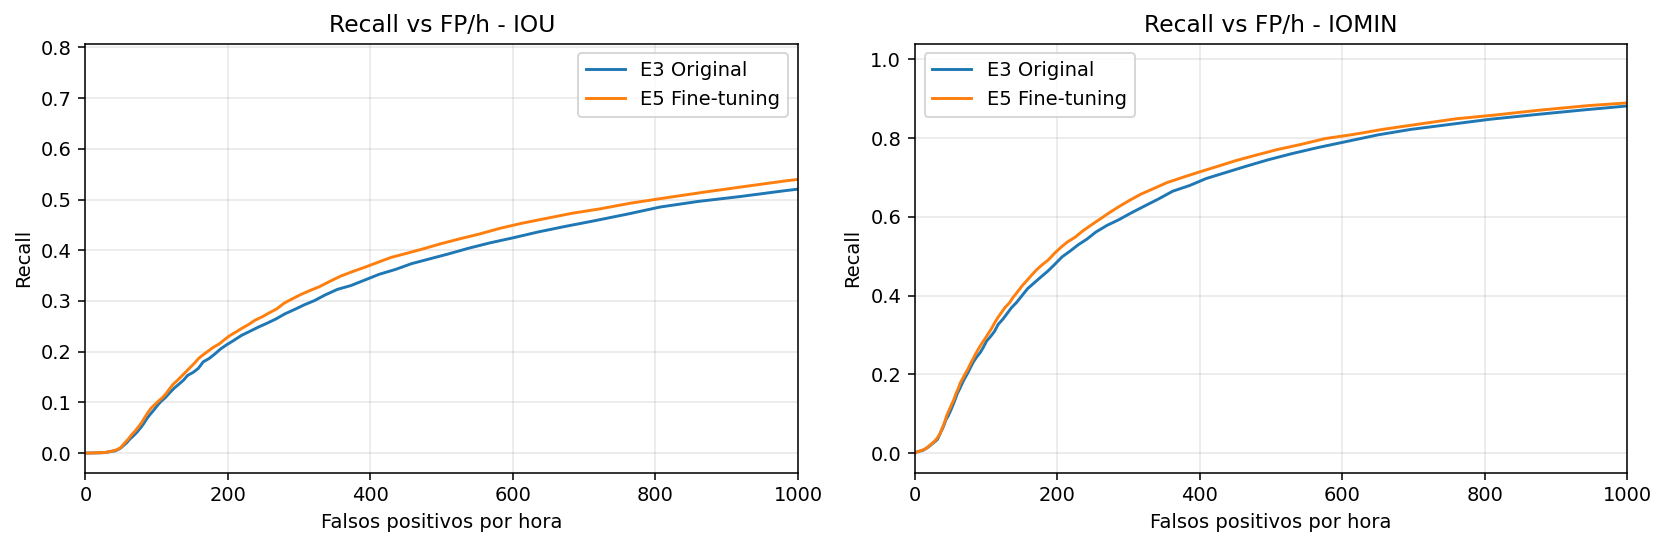

Resultados guardados: /content/drive/MyDrive/Proyecto_Aves/experiments/detector/E5_RFDETR_Negativas/entrenamiento_v2/evaluacion_operativa_v1/20f2d1c6100b


In [23]:
comparacion = []

for criterio in ("iou", "iomin"):
    original = curvas.loc[(curvas["modelo"] == "E3 Original") & (curvas["criterio"] == criterio) & np.isclose(curvas["umbral"], 0.5)].iloc[0]
    candidatos = curvas.loc[(curvas["modelo"] == "E5 Fine-tuning") & (curvas["criterio"] == criterio) & (curvas["recall"] >= original["recall"])]
    if candidatos.empty:
        print(f"{criterio}: E5 no alcanza el recall de E3 en los umbrales evaluados")
        continue

    ajustado = candidatos.loc[candidatos["fp_h"].idxmin()]
    comparacion.append({
        "criterio": criterio,
        "recall_E3": original["recall"],
        "fp_h_E3": original["fp_h"],
        "umbral_E5": ajustado["umbral"],
        "recall_E5": ajustado["recall"],
        "fp_h_E5": ajustado["fp_h"],
        "reduccion_fp_h_pct": 100 * (original["fp_h"] - ajustado["fp_h"]) / original["fp_h"]
    })

comparacion = pd.DataFrame(comparacion)
comparacion.to_csv(DIR_EVAL / "comparacion_recall_equivalente.csv", index=False)
display(comparacion.round(4))
fig, ax = plt.subplots(1, 2, figsize=(12, 4), dpi=140)
for eje, criterio in zip(ax, ("iou", "iomin")):
    for nombre, grupo in curvas.loc[curvas["criterio"] == criterio].groupby("modelo"):
        eje.plot(grupo["fp_h"], grupo["recall"], label=nombre)

    eje.set_title(f"Recall vs FP/h - {criterio.upper()}")
    eje.set_xlabel("Falsos positivos por hora")
    eje.set_ylabel("Recall")
    eje.set_xlim(0, 1000)
    eje.grid(alpha=0.3)
    eje.legend()

plt.tight_layout()
plt.savefig(DIR_EVAL / "comparacion_recall_fp_h.png", dpi=180, bbox_inches="tight")
plt.show()
print("Resultados guardados:", DIR_EVAL)

### Conclusiones del fine-tuning

El ajuste fino de RF-DETR Nano con 6.000 ventanas positivas y 1.798 ventanas sin anotaciones permitió mejorar moderadamente su comportamiento operativo sobre las grabaciones de validación, con un recall equivalente al modelo original, E5 redujo los falsos positivos por hora un 9,14 % utilizando IoU y un 6,72 % utilizando IoMin. Asimismo, se observó una disminución considerable en el número de detecciones generadas antes de aplicar los umbrales operativos de confianza

Aunque el AP50 de validación no mejoró respecto al entrenamiento original, los resultados operativos favorecen al modelo ajustado. Sin embargo, la cantidad de falsas detecciones continúa siendo elevada y no puede atribuirse toda la mejora exclusivamente a la incorporación de ventanas negativas.

Se selecciona provisionalmente RF-DETR Nano E5 para continuar con la integración del sistema. No se realizarán nuevos entrenamientos del detector en esta etapa, su rendimiento definitivo se evaluará posteriormente sobre el conjunto de prueba reservado.